In [3]:
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision import datasets, transforms

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

trainset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

testset = datasets.MNIST(
    'MNIST_data/',
    download=True,
    train=False,
    transform=transform
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

In [6]:
model = nn.Sequential(
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

model

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=10, bias=True)
)

In [7]:
criterion = nn.CrossEntropyLoss()

In [8]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

In [9]:
images, labels = next(iter(trainloader))

images = images.view(images.shape[0], -1)

images.shape

torch.Size([64, 784])

In [10]:
logits = model(images)
loss = criterion(logits, labels)

loss

tensor(2.3006, grad_fn=<NllLossBackward0>)

In [11]:
optimizer.zero_grad()
loss.backward()

In [12]:
optimizer.step()

In [13]:
logits = model(images)
loss = criterion(logits, labels)

loss

tensor(2.2950, grad_fn=<NllLossBackward0>)

In [14]:
optimizer.zero_grad()
loss.backward()

In [15]:
model[0].weight.grad.shape

torch.Size([128, 784])

In [16]:
optimizer.step()

In [17]:
logits = model(images)
new_loss = criterion(logits, labels)

new_loss

tensor(2.2897, grad_fn=<NllLossBackward0>)

In [18]:
print(f"Loss anterior: {loss.item():.10f}")
print(f"Loss nueva:    {new_loss.item():.10f}")

Loss anterior: 2.2950425148
Loss nueva:    2.2897315025


In [19]:

epochs = 5
train_losses = []

for epoch in range(epochs):
    running_loss = 0

    for images, labels in trainloader:
        images = images.view(images.shape[0], -1)

        optimizer.zero_grad()

        logits = model(images)
        loss = criterion(logits, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(trainloader)
    train_losses.append(epoch_loss)

    print(f"Época {epoch + 1}: pérdida = {epoch_loss:.4f}")


Época 1: pérdida = 0.9719
Época 2: pérdida = 0.3828
Época 3: pérdida = 0.3276
Época 4: pérdida = 0.2969
Época 5: pérdida = 0.2716


In [20]:
correct = 0
total = 0

with torch.no_grad():
    for images, labels in testloader:
        images = images.view(images.shape[0], -1)

        logits = model(images)
        predictions = torch.argmax(logits, dim=1)

        total += labels.size(0)
        correct += (predictions == labels).sum().item()

accuracy = correct / total

print(f"Accuracy: {accuracy:.4f}")
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 0.9268
Accuracy: 92.68%


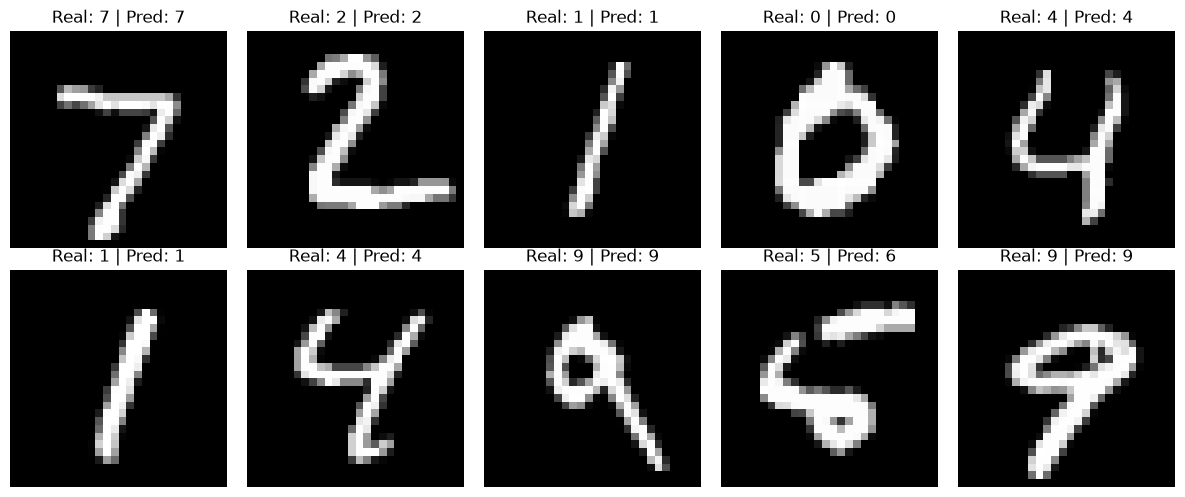

In [21]:

# Tomar un lote de imágenes del conjunto de prueba
images, labels = next(iter(testloader))

# Preparar las imágenes para la red neuronal
images_flat = images.view(images.shape[0], -1)

# Obtener las predicciones
with torch.no_grad():
    logits = model(images_flat)
    predictions = torch.argmax(logits, dim=1)

# Mostrar algunas imágenes y sus predicciones
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].numpy().squeeze(), cmap="gray")
    
    real = labels[i].item()
    predicho = predictions[i].item()
    
    ax.set_title(f"Real: {real} | Pred: {predicho}")
    ax.axis("off")

plt.tight_layout()
plt.show()


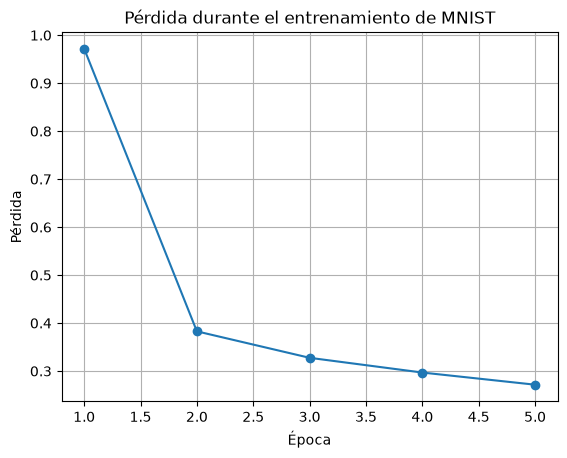

In [22]:

import matplotlib.pyplot as plt

plt.plot(range(1, len(train_losses) + 1), train_losses, marker="o")
plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento de MNIST")
plt.grid(True)
plt.show()
